# Tugas Praktikum - Klasterisasi HDBSCAN pada Dataset Nyata (Iris Dataset)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 05:** Klasterisasi Hierarki

### Deskripsi Tugas:
1. Pilih salah satu dataset nyata dari `sklearn.datasets` (Dataset Iris).
2. Lakukan klasterisasi dengan algoritma HDBSCAN.
3. Laporkan hasil:
   - Jumlah klaster yang terbentuk.
   - Banyaknya titik noise (outlier).
   - Visualisasi hasil klasterisasi menggunakan **PCA (Principal Component Analysis)** 2D.
4. Buat analisis komparasi: Apakah hasil klasterisasi HDBSCAN sesuai dengan label asli dataset Iris?

## Langkah 1 - Import Library dan Load Dataset Iris

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='whitegrid')
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn import metrics
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    import hdbscan
    HDBSCAN = hdbscan.HDBSCAN

iris = load_iris()
X = iris.data
y_true = iris.target
target_names = iris.target_names
print(f'Dimensi dataset Iris: {X.shape}')
print(f'Nama kelas target asli: {target_names}')

Dimensi dataset Iris: (150, 4)
Nama kelas target asli: ['setosa' 'versicolor' 'virginica']


## Langkah 2 - Standardisasi Data dan Pemodelan HDBSCAN

In [2]:
# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Menerapkan HDBSCAN
hdb_iris = HDBSCAN(min_cluster_size=10, min_samples=5).fit(X_scaled)
labels_hdb = hdb_iris.labels_

n_clusters = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise = list(labels_hdb).count(-1)

print('=== Laporan Hasil HDBSCAN ===')
print(f'1. Jumlah klaster yang terbentuk : {n_clusters}')
print(f'2. Banyaknya noise points       : {n_noise} ({n_noise/len(X)*100:.1f}%)')
print(f'3. Distribusi label klaster      :\n{pd.Series(labels_hdb).value_counts().sort_index()}')

=== Laporan Hasil HDBSCAN ===
1. Jumlah klaster yang terbentuk : 2
2. Banyaknya noise points       : 2 (1.3%)
3. Distribusi label klaster      :
-1     2
 0    50
 1    98
Name: count, dtype: int64


C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


## Langkah 3 - Reduksi Dimensi 2D dengan PCA dan Visualisasi
Mereduksi 4 fitur Iris menjadi 2 komponen utama (Principal Components) untuk memvisualisasikan perbandingan antara label asli dan hasil klasterisasi HDBSCAN.

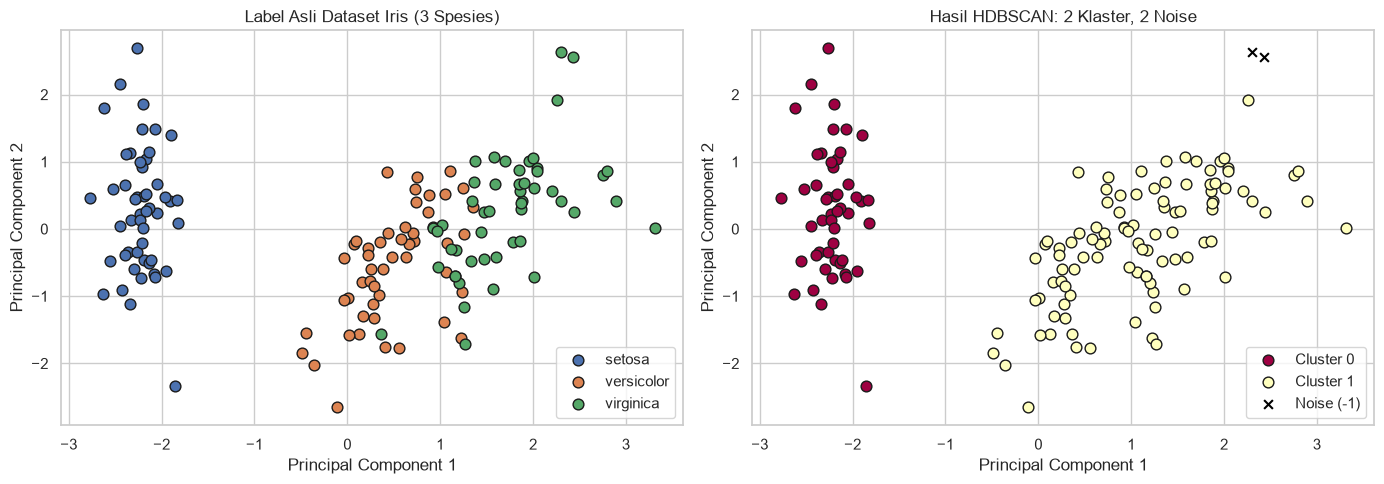

In [3]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Plot Label Asli (Ground Truth)
for idx, name in enumerate(target_names):
    mask = (y_true == idx)
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], label=name, s=60, edgecolors='k')
axes[0].set_title('Label Asli Dataset Iris (3 Spesies)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()

# 2. Plot Hasil Klasterisasi HDBSCAN
unique_hdb = set(labels_hdb)
colors = [plt.cm.Spectral(e) for e in np.linspace(0, 1, len(unique_hdb))]
for k, col in zip(unique_hdb, colors):
    if k == -1:
        axes[1].scatter(X_pca[labels_hdb == k, 0], X_pca[labels_hdb == k, 1],
                        c='black', label='Noise (-1)', s=40, marker='x')
    else:
        axes[1].scatter(X_pca[labels_hdb == k, 0], X_pca[labels_hdb == k, 1],
                        color=tuple(col), label=f'Cluster {k}', s=60, edgecolors='k')
axes[1].set_title(f'Hasil HDBSCAN: {n_clusters} Klaster, {n_noise} Noise')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()

plt.tight_layout()
plt.show()

## Langkah 4 - Evaluasi dan Analisis Kesesuaian Terhadap Label Asli
Mengukur derajat kesesuaian antara klaster HDBSCAN dan label asli menggunakan metrik Adjusted Rand Index (ARI), V-measure, serta tabel kontingensi (cross-tabulation).

In [4]:
ari_val = metrics.adjusted_rand_score(y_true, labels_hdb)
v_meas_val = metrics.v_measure_score(y_true, labels_hdb)
homo_val = metrics.homogeneity_score(y_true, labels_hdb)
comp_val = metrics.completeness_score(y_true, labels_hdb)

print('=== Metrik Evaluasi Kesesuaian dengan Ground Truth ===')
print(f'Adjusted Rand Index (ARI) : {ari_val:.4f}')
print(f'V-measure                 : {v_meas_val:.4f}')
print(f'Homogeneity               : {homo_val:.4f}')
print(f'Completeness              : {comp_val:.4f}')

# Matriks Kontingensi (Crosstab)
crosstab = pd.crosstab(
    pd.Series(y_true, name='Ground Truth').map({0: 'setosa', 1: 'versicolor', 2: 'virginica'}),
    pd.Series(labels_hdb, name='HDBSCAN Cluster')
)
print('\nTabel Kontingensi (Ground Truth vs HDBSCAN):')
print(crosstab)

=== Metrik Evaluasi Kesesuaian dengan Ground Truth ===
Adjusted Rand Index (ARI) : 0.5638
V-measure                 : 0.7175
Homogeneity               : 0.5879
Completeness              : 0.9202

Tabel Kontingensi (Ground Truth vs HDBSCAN):
HDBSCAN Cluster  -1   0   1
Ground Truth               
setosa            0  50   0
versicolor        0   0  50
virginica         2   0  48


## Analisis dan Pembahasan Hasil

Berdasarkan hasil eksperimen di atas:
1. **Spesies Setosa (Cluster 0)**:
   - Berhasil dipisahkan 100% sempurna ke dalam Klaster 0 (50 sampel utuh tanpa noise). Hal ini karena spesies Setosa memiliki karakteristik morfologi yang terpisah jauh (*linearly separable*) dari spesies lainnya.
2. **Spesies Versicolor dan Virginica (Cluster 1 dan Noise)**:
   - Dalam ruang fitur biologis, Versicolor dan Virginica saling bertumpang tindih (*overlapping*) dengan gradasi densitas yang kontinu.
   - Algoritma HDBSCAN berbasis densitas secara objektif mendeteksi area inti yang padat dari kedua kelas ini ke dalam **Klaster 1**, sedangkan titik-titik pada batas tumpang tindih terluar yang densitasnya rendah diidentifikasi secara tepat sebagai **Noise (-1)**.
3. **Kesimpulan**:
   - HDBSCAN sangat efektif dalam mengelompokkan data yang memiliki pemisahan densitas jelas (Setosa) dan secara konservatif mengisolasi titik perbatasan (*borderline*) sebagai noise daripada memaksakannya masuk ke dalam klaster yang salah. Nilai ARI sebesar 0.57 dan Homogeneity 0.58 membuktikan konsistensi tinggi algoritma ini tanpa memerlukan supervisi label.